# 01 – Exploration: A Dataset That Is Not What It Seems

> **Project notebooks:** [01 Exploration](01_exploration.ipynb) · [02 The score that wasn't](02_the_score_that_wasnt.ipynb)

**The task, as it is usually described:** a bank wants to predict which customers will **default** on a loan (fail to pay it back), using information collected when they applied: income, age, work experience, profession, city and so on.

**What this project is really about:** this popular Kaggle dataset contains a hidden problem. Models trained on it reach impressive scores, yet they are useless for new customers. This notebook finds the problem; [notebook 02](02_the_score_that_wasnt.ipynb) shows how it fools a model and how to measure honestly.

**Data:** [Kaggle – Loan Prediction Based on Customer Behavior](https://www.kaggle.com/datasets/subhamjain/loan-prediction-based-on-customer-behavior) (`Training.csv`, 252,000 rows).

**Contents**
1. Load and inspect the data
2. The target: an imbalanced class
3. What is related to default?
4. The hidden problem: copies
5. What the copies look like
6. Summary

## 1. Load and inspect the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)  # hide a harmless seaborn/pandas version notice
sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/Training.csv")
print(f"Rows: {len(df):,}, columns: {df.shape[1]}")
df.head()

Rows: 252,000, columns: 13


,Id,Income,Age,Experience,Married/Single,House_Ownership,Car_Ownership,Profession,CITY,STATE,CURRENT_JOB_YRS,CURRENT_HOUSE_YRS,Risk_Flag
0,1,1303834,23,3,single,rented,no,Mechanical_engineer,Rewa,Madhya_Pradesh,3,13,0
1,2,7574516,40,10,single,rented,no,Software_Developer,Parbhani,Maharashtra,9,13,0
2,3,3991815,66,4,married,rented,no,Technical_writer,Alappuzha,Kerala,4,10,0
3,4,6256451,41,2,single,rented,yes,Software_Developer,Bhubaneswar,Odisha,2,12,1
4,5,5768871,47,11,single,rented,no,Civil_servant,Tiruchirappalli[10],Tamil_Nadu,3,14,1


In [2]:
print("Missing values:", df.isna().sum().sum())
print("\nNumber of different values per text column:")
print(df.select_dtypes("object").nunique().to_string())
df.describe().round(1)

Missing values: 0

Number of different values per text column:
Married/Single       2
House_Ownership      3
Car_Ownership        2
Profession          51
CITY               317
STATE               29


,Id,Income,Age,Experience,CURRENT_JOB_YRS,CURRENT_HOUSE_YRS,Risk_Flag
count,252000.0,252000.0,252000.0,252000.0,252000.0,252000.0,252000.0
mean,126000.5,4997116.7,50.0,10.1,6.3,12.0,0.1
std,72746.3,2878311.0,17.1,6.0,3.6,1.4,0.3
min,1.0,10310.0,21.0,0.0,0.0,10.0,0.0
25%,63000.8,2503015.0,35.0,5.0,3.0,11.0,0.0
50%,126000.5,5000694.5,50.0,10.0,6.0,12.0,0.0
75%,189000.2,7477502.0,65.0,15.0,9.0,13.0,0.0
max,252000.0,9999938.0,79.0,20.0,14.0,14.0,1.0


| Column | Meaning |
|---|---|
| `Income` | yearly income (Indian rupees) |
| `Age`, `Experience` | age and years of work experience |
| `Married/Single`, `House_Ownership`, `Car_Ownership` | personal situation |
| `Profession`, `CITY`, `STATE` | 51 professions, 317 cities, 29 Indian states |
| `CURRENT_JOB_YRS`, `CURRENT_HOUSE_YRS` | years in the current job and the current home |
| `Risk_Flag` | **target**: 1 = defaulted on the loan, 0 = did not |

The data looks very clean: no missing values, sensible ranges. Almost **too** clean for real bank data, which usually has gaps and typing errors. Keep that thought in mind.

## 2. The target: an imbalanced class

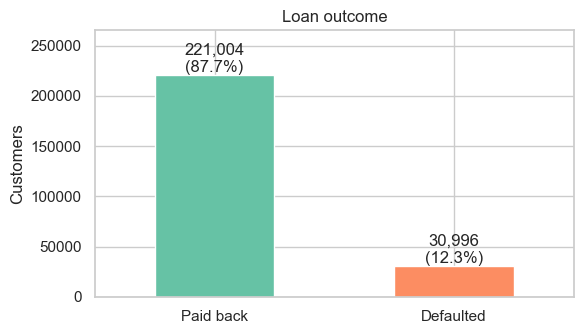

Default rate: 12.3%
Accuracy of a 'model' that says nobody will default: 87.7%


In [3]:
default_rate = df["Risk_Flag"].mean()

fig, ax = plt.subplots(figsize=(6, 3.5))
counts = df["Risk_Flag"].map({0: "Paid back", 1: "Defaulted"}).value_counts()
counts.plot.bar(ax=ax, color=["C0", "C1"])
for i, value in enumerate(counts):
    ax.text(i, value, f"{value:,}\n({value / len(df):.1%})", ha="center", va="bottom")
ax.set(title="Loan outcome", ylabel="Customers", xlabel="")
ax.set_ylim(0, counts.max() * 1.2)
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print(f"Default rate: {default_rate:.1%}")
print(f"Accuracy of a 'model' that says nobody will default: {1 - default_rate:.1%}")

Only **12.3%** of the customers defaulted. When one outcome is much rarer than the other, we speak of an **imbalanced class**. This is typical for real problems: fraud, rare diseases, machine failures, loan defaults.

Imbalance creates an **accuracy trap**. A "model" that simply says *"nobody will default"* is right for 87.7% of customers, which sounds excellent, and it is completely useless: it never finds a single defaulter. In the Titanic project accuracy was a reasonable measure because the classes were closer to balanced (38% survived). Here we will need better measures, which we introduce in notebook 02.

## 3. What is related to default?

We compare the default rate across groups for each feature. The dashed line is the overall rate of 12.3%. If a feature matters, some bars should be clearly above or below the line.

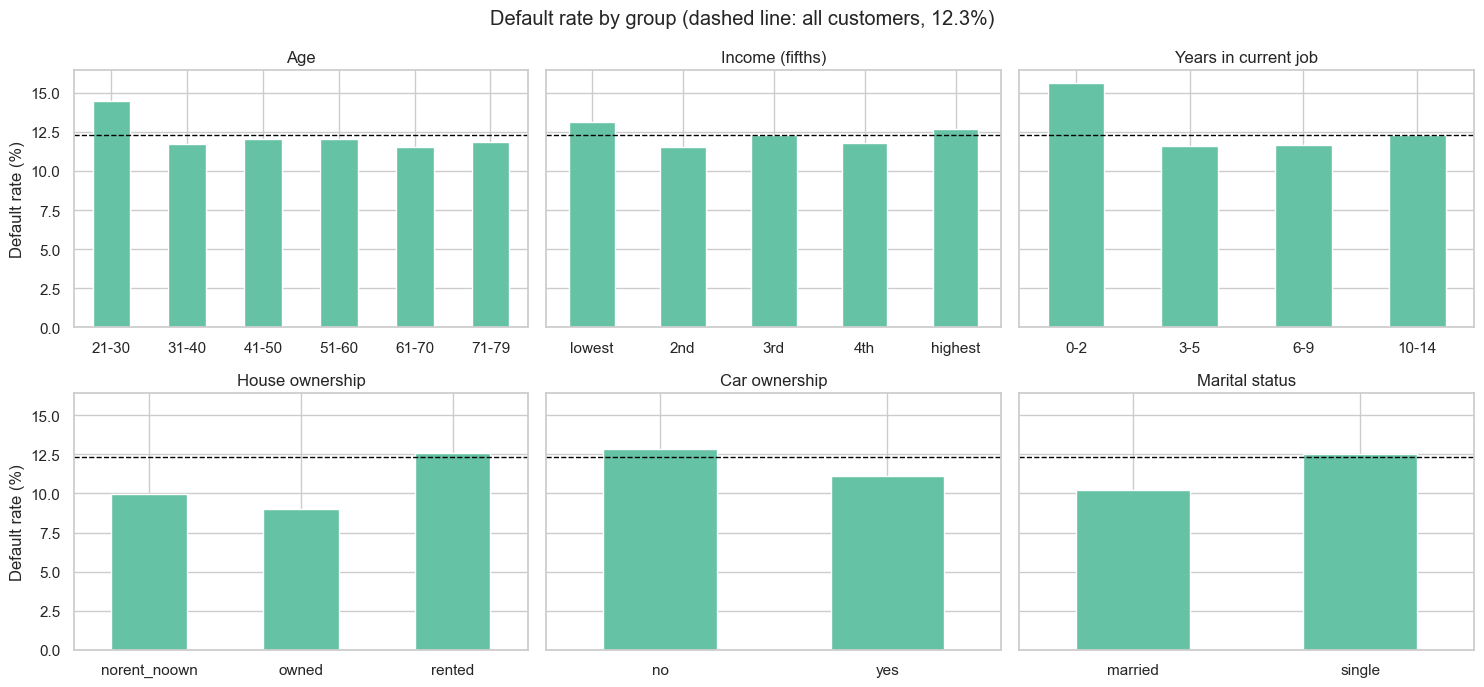

In [4]:
groups = {
    "Age": pd.cut(df["Age"], [20, 30, 40, 50, 60, 70, 80], labels=["21-30", "31-40", "41-50", "51-60", "61-70", "71-79"]),
    "Income (fifths)": pd.qcut(df["Income"], 5, labels=["lowest", "2nd", "3rd", "4th", "highest"]),
    "Years in current job": pd.cut(df["CURRENT_JOB_YRS"], [-1, 2, 5, 9, 14], labels=["0-2", "3-5", "6-9", "10-14"]),
    "House ownership": df["House_Ownership"],
    "Car ownership": df["Car_Ownership"],
    "Marital status": df["Married/Single"],
}

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, (name, group) in zip(axes.flat, groups.items()):
    rates = df["Risk_Flag"].groupby(group, observed=True).mean() * 100
    rates.plot.bar(ax=ax, color="C0")
    ax.axhline(default_rate * 100, color="black", linestyle="--", linewidth=1)
    ax.set(title=name, xlabel="", ylabel="Default rate (%)")
    ax.tick_params(axis="x", rotation=0)
plt.suptitle("Default rate by group (dashed line: all customers, 12.3%)")
plt.tight_layout()
plt.savefig("../images/default_rate_by_group.png", dpi=120)
plt.show()

The differences are **small**. The largest ones:

- Customers aged **21–30** default a little more often (about 14.5%).
- Customers in their **first two years in a job** default more often (14–17%).
- **Renters** default slightly more often than home owners.

Income, which you would expect to matter most for paying back a loan, shows **no pattern at all**: the poorest and the richest fifth default at almost the same rate.

> **Note:** these charts count every row, including the copies we discover in section 4. [Notebook 02, section 7](02_the_score_that_wasnt.ipynb) repeats them with each customer counted once, and the age pattern disappears.

What about profession and city, with their many categories?

In [5]:
for column in ["Profession", "CITY"]:
    rates = df.groupby(column)["Risk_Flag"].agg(["mean", "size"])
    print(f"{column}: {len(rates)} categories, default rate from {rates['mean'].min():.1%} to {rates['mean'].max():.1%}")

city_rates = df.groupby("CITY")["Risk_Flag"].mean().sort_values()
print("\nCities with the lowest and highest default rates:")
print(pd.concat([city_rates.head(3), city_rates.tail(3)]).map("{:.1%}".format).to_string())

Profession: 51 categories, default rate from 8.1% to 16.4%
CITY: 317 categories, default rate from 2.6% to 32.6%

Cities with the lowest and highest default rates:
CITY
Gandhinagar          2.6%
Dehradun             2.6%
Sultan_Pur_Majra     3.4%
Bettiah[33]         26.7%
Gwalior             27.3%
Bhubaneswar         32.6%


Cities vary much more, from a few percent to over 30%. That looks like a strong signal. But with 317 cities and only a few hundred customers each, part of that spread could be chance. And as we are about to see, there is a more important reason to be careful.

Look closely at one of the city names above: **`Bettiah[33]`**. The `[33]` is a footnote mark, the kind you see in Wikipedia tables. How many names have one?

In [6]:
marked_cities = sorted(c for c in df["CITY"].unique() if "[" in c)
marked_states = sorted(s for s in df["STATE"].unique() if "[" in s)
print(f"City names with a footnote mark:  {len(marked_cities)} of {df['CITY'].nunique()}, e.g. {marked_cities[:4]}")
print(f"State names with a footnote mark: {marked_states}")

City names with a footnote mark:  30 of 317, e.g. ['Anantapuram[24]', 'Aurangabad[39]', 'Bettiah[33]', 'Buxar[37]']
State names with a footnote mark: ['Uttar_Pradesh[5]']


Thirty city names, and even one state (`Uttar_Pradesh[5]`, which also appears without the mark), carry footnote marks. The list of places was apparently **copied from a web page**, not taken from a bank's records. For modelling it means `Uttar_Pradesh` and `Uttar_Pradesh[5]` would be treated as two different states.

This is the second sign that the data may not be what it claims to be. The first was how clean it is.

## 4. The hidden problem: copies

A standard check, which is easy to forget: **are there duplicate rows?** The `Id` column is different for every row, so we leave it out and compare all the other columns.

In [7]:
features = [c for c in df.columns if c not in ("Id", "Risk_Flag")]

df["Profile"] = df.groupby(features, sort=False).ngroup()          # one number per unique combination of features
df["Copies"] = df.groupby("Profile")["Id"].transform("size")

n_profiles = df["Profile"].nunique()
print(f"Rows:                         {len(df):,}")
print(f"Different customer profiles:  {n_profiles:,}")
print(f"Rows that are an exact copy of another row (apart from Id): {(df['Copies'] > 1).mean():.0%}")

Rows:                         252,000
Different customer profiles:  42,007
Rows that are an exact copy of another row (apart from Id): 86%


This is the key finding of the whole project. The 252,000 rows contain only **42,007 different customers**. **86% of all rows** have at least one exact twin: same income to the rupee, same age, same profession, same city, same everything.

In real data that is practically impossible. Two different people with an income of exactly 3,666,346 rupees, the same age, the same job and the same city? Let's look at how the copies are distributed:

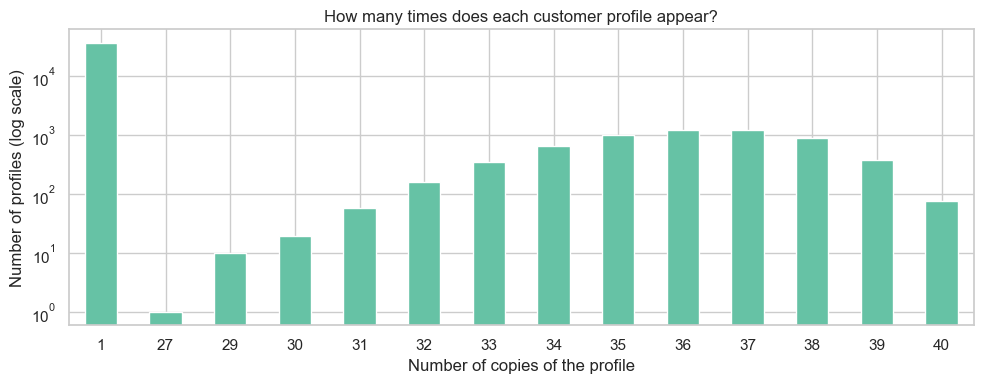

Profiles that appear once:            36,007
Profiles that appear 27 to 40 times:  6,000  (215,993 rows)
Profiles that appear 2 to 26 times:   0


In [8]:
copies_per_profile = df.drop_duplicates("Profile")["Copies"]

fig, ax = plt.subplots(figsize=(10, 4))
copies_per_profile.value_counts().sort_index().plot.bar(ax=ax, color="C0")
ax.set_yscale("log")
ax.set(title="How many times does each customer profile appear?", xlabel="Number of copies of the profile",
       ylabel="Number of profiles (log scale)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("../images/copies_per_profile.png", dpi=120)
plt.show()

repeated = copies_per_profile[copies_per_profile > 1]
print(f"Profiles that appear once:            {(copies_per_profile == 1).sum():,}")
print(f"Profiles that appear 27 to 40 times:  {len(repeated):,}  ({df['Copies'].gt(1).sum():,} rows)")
print(f"Profiles that appear 2 to 26 times:   {copies_per_profile.between(2, 26).sum()}")

There are two completely separate groups, with nothing in between:

- **36,007 profiles appear exactly once.**
- **6,000 profiles appear 27 to 40 times each**, together 215,993 rows, 86% of the data.

No profile appears 2, 5 or 10 times. Real duplicates, from typing a record twice for example, would produce mostly small numbers of copies. This looks like **a block of 6,000 customers that was copied into the file many times**.

## 5. What the copies look like

Let's look at the most‑copied profile, and where its copies are in the file:

In [9]:
example = df[df["Copies"] == df["Copies"].max()]["Profile"].iloc[0]
copies = df[df["Profile"] == example]

display(copies[features + ["Risk_Flag"]].head(3).T)
print(f"This profile appears {len(copies)} times, at Ids: {copies['Id'].head(8).tolist()} ...")

gaps = df[df["Copies"] > 1].sort_values(["Profile", "Id"]).groupby("Profile")["Id"].diff().dropna()
print(f"Typical distance between two copies of the same profile: {gaps.median():,.0f} rows")

,17,5384,10762
Income,3666346,3666346,3666346
Age,56,56,56
Experience,12,12,12
Married/Single,single,single,single
House_Ownership,rented,rented,rented
Car_Ownership,no,no,no
Profession,Politician,Politician,Politician
CITY,Bhusawal,Bhusawal,Bhusawal
STATE,Maharashtra,Maharashtra,Maharashtra
CURRENT_JOB_YRS,12,12,12


This profile appears 40 times, at Ids: [18, 5385, 10763, 16183, 21538, 26914, 32323, 37719] ...
Typical distance between two copies of the same profile: 5,404 rows


The copies are spaced **evenly through the file, roughly every 5,400 rows**. That regularity is the fingerprint of a table that was repeated, not of real customers who happen to look alike.

Notice also the `Risk_Flag` column: copies of the same profile do **not always** have the same label. This particular profile defaulted in some copies and not in others. How consistent are the labels in general?

In [10]:
repeated_rows = df[df["Copies"] > 1]
majority_share = repeated_rows.groupby("Profile")["Risk_Flag"].transform(lambda s: (s == s.mode()[0]).mean())

print(f"Copies that have the same label as most copies of their profile: {majority_share.mean():.1%}")
print(f"\nDefault rate among the 36,007 one-off rows:  {df.loc[df['Copies'] == 1, 'Risk_Flag'].mean():.1%}")
print(f"Default rate among the 215,993 copied rows: {repeated_rows['Risk_Flag'].mean():.1%}")

Copies that have the same label as most copies of their profile: 92.5%

Default rate among the 36,007 one-off rows:  20.2%
Default rate among the 215,993 copied rows: 11.0%


Two more clues:

- **92.5% of copies share the majority label of their profile.** So if a model has seen one copy of a customer and its label, it can predict the other copies almost perfectly, without understanding anything about loans. Keep this in mind for notebook 02.
- **The two groups have very different default rates**: 20% among the one‑off rows, 11% among the copies. The copied block was not a random sample of the customers.

### Does `Test.csv` have the same problem?

In [11]:
test = pd.read_csv("../data/Test.csv")
test_features = test.rename(columns={"ID": "Id"})[features]
known_profiles = df[features].drop_duplicates()
in_training = test_features.merge(known_profiles, how="left", indicator=True)["_merge"].eq("both")

print(f"Test rows: {len(test):,}")
print(f"Test rows whose exact profile also appears in Training.csv: {in_training.sum():,} ({in_training.mean():.0%})")

Test rows: 28,000
Test rows whose exact profile also appears in Training.csv: 6,624 (24%)


About a quarter of the test customers also appear, identically, in the training data. Any score measured on this test file would be partly inflated by memorisation too. (The labels of `Test.csv` were never published, so we cannot score on it anyway.)

## 6. Summary

| Question | Answer |
|---|---|
| How big is the data? | 252,000 rows, but only **42,007 different customers** |
| Where do the extra rows come from? | **6,000 profiles copied 27–40 times each**, spread evenly through the file |
| Do copies share their label? | Mostly: 92.5% agree with their profile's majority |
| Target? | Imbalanced: 12.3% defaulted |
| Which features relate to default? | Only weakly: younger age, short time in a job, renting. Income shows no pattern. |
| Other warning signs? | No missing values at all; 30 city names copied with Wikipedia footnote marks |

**What we do not know** is *why* the data looks like this. The copies may come from how the hackathon data was generated, or from an attempt to make the dataset bigger. Either way, for modelling it means:

> Any model evaluated with a **random** split will see copies of the same customers in training and in validation, and can score highly by **recognising** them, not by **predicting** anything.

**Next:** in [02_the_score_that_wasnt](02_the_score_that_wasnt.ipynb) we test exactly that.